# Quartiles and the Interquartile Range

*Calculate quartiles with a stated convention and interpret IQR fences and boxplot whiskers.*


## Quartiles Describe Positions in Ordered Data

$Q_1$, $Q_2$, and $Q_3$ correspond to the 25th, 50th, and 75th percentiles.
Small datasets can produce different quartiles under different conventions.
The lecture compares medians of the halves, excluding the central value,
with an interpolated calculation for the values 1 through 7.

NumPy's `method="linear"` uses the zero-based position $(n-1)q$ for quantile
level $q$, interpolating between adjacent observations. This formula is more
general than always including the median in both halves.


In [1]:
import numpy as np

values = np.arange(1, 8, dtype=float)
linear_quartiles = np.quantile(values, [0.25, 0.5, 0.75], method="linear")
exclusive_halves = np.array(
    [np.median(values[:3]), np.median(values), np.median(values[4:])]
)
print("Linear quartiles:", linear_quartiles)
print("Medians of halves excluding the center:", exclusive_halves)
print("Linear IQR:", linear_quartiles[2] - linear_quartiles[0])


Linear quartiles: [2.5 4.  5.5]
Medians of halves excluding the center: [2. 4. 6.]
Linear IQR: 3.0


Linear interpolation gives 2.5, 4, and 5.5, with IQR 3. Excluding the
central value when taking half-medians gives 2, 4, and 6. The difference is a
convention difference, not a coding error.


## IQR Fences Identify Unusual Observations

The interquartile range is $IQR=Q_3-Q_1$, a spread measure focused on the middle
of the data. The common boxplot fences are

$$L=Q_1-1.5\,IQR,\qquad U=Q_3+1.5\,IQR.$$

Values strictly outside those bounds are flagged. The multiplier is a
convention for exploration, not a proof that a record is wrong.


In [2]:
session_minutes = np.array([20, 25, 30, 30, 35, 40, 45, 50, 55, 120], dtype=float)
q1, median, q3 = np.quantile(session_minutes, [0.25, 0.5, 0.75], method="linear")
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
flagged = (session_minutes < lower_fence) | (session_minutes > upper_fence)
print("Q1, median, Q3:", q1, median, q3)
print("IQR:", iqr)
print("Fences:", lower_fence, upper_fence)
print("Flagged minutes:", session_minutes[flagged])


Q1, median, Q3: 30.0 37.5 48.75
IQR: 18.75
Fences: 1.875 76.875
Flagged minutes: [120.]


The quartiles are 30, 37.5, and 48.75 minutes. The IQR is 18.75, with
fences 1.875 and 76.875. Only the 120-minute session lies outside the fences.


## A Boxplot Separates the Box, Whiskers, and Flags

The box spans Q1 to Q3 and the line inside marks the median. With `whis=1.5`,
whiskers extend to the most extreme observed values still inside the fences;
they do not normally end at the numerical fences themselves.


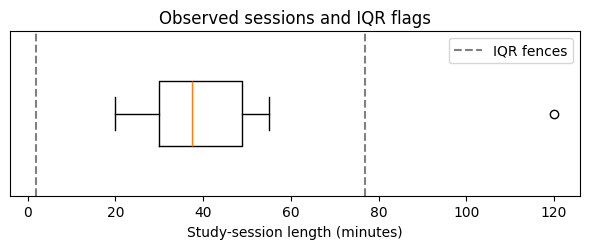

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6.0, 2.6), dpi=100)
ax.boxplot(session_minutes, orientation="horizontal", whis=1.5, widths=0.4)
ax.axvline(lower_fence, color="gray", linestyle="--", label="IQR fences")
ax.axvline(upper_fence, color="gray", linestyle="--")
ax.set_xlabel("Study-session length (minutes)")
ax.set_yticks([])
ax.set_title("Observed sessions and IQR flags", fontsize=12)
ax.legend(fontsize=10)
fig.tight_layout()
plt.show()
plt.close(fig)


The whiskers end at 20 and 55 minutes. The separate point at 120 is a
candidate for review, while the dashed fence positions are 1.875 and 76.875.
The long session remains part of the dataset.


State the quartile convention. IQR fences flag unusually distant values, while boxplot whiskers end at actual observations inside those fences.

[Related explanation in the source lecture](https://www.youtube.com/watch?v=9bM65kxOwPA&t=2702s).
